# TP 2 : Simulation Multi-Agent avec Mesa 3
## Sujet : Formation de l'opinion publique

Dans ce TP, nous allons utiliser **Mesa 3**, le framework Python pour la modélisation basée sur les agents. 

### Rappel de la syntaxe Mesa 3 :
Par rapport aux anciennes versions, Mesa 3 apporte des simplifications majeures :
* **Gestion des agents :** Les agents s'enregistrent automatiquement dans le modèle lors de l'appel à `super().__init__(model)`.
* **Activation (Scheduler) :** L'ancien module `time` (avec `RandomActivation`) est remplacé. On utilise désormais l'attribut `self.agents` (un objet `AgentSet`). Pour activer tous les agents dans un ordre aléatoire, on appelle simplement `self.agents.shuffle_do("step")` dans la méthode `step()` du modèle.
* **Espace :** Les agents sont placés dans une grille (ex: `mesa.space.MultiGrid`). Les interactions spatiales se font via les coordonnées des agents.
* **Collecte de données :** Le `DataCollector` permet toujours d'extraire les variables du modèle et des agents à chaque "tick" (pas de temps) pour l'analyse via `pandas`.

## 1. Description du Modèle (Protocole ODD)

### Phénomène à modéliser
Dans les sociétés modernes, l'opinion publique se forme par les interactions entre individus. À l'aide d'un SMA, nous étudions comment ces interactions locales peuvent produire un consensus, une polarisation ou des groupes d'opinion.

### Overview (Vue d'ensemble)
* **Objectif :** Simuler l'évolution des opinions individuelles dans une population afin d'étudier l'émergence de consensus, de polarisation ou de groupes d'opinion.
* **Entités :** Les agents représentent des individus.
* **Variables d'état :** L'opinion $o_i \in [0,1]$ (0 = totalement contre, 0.5 = neutre, 1 = totalement pour).
* **Processus :** À chaque tick, un agent observe les opinions de ses voisins $\mathcal{N}_i$, calcule leur moyenne $\bar{o}_{\mathcal{N}_i}^{\,t}$, et ajuste son opinion : 
  $o_i^{t+1}=o_i^t+\alpha\left(\bar{o}_{\mathcal{N}_i}^{\,t}-o_i^t\right)$ avec $\alpha\in[0,1]$.

### Design Concepts
* **Émergence :** Consensus, polarisation ou clusters émergent sans coordination centrale.
* **Interaction :** Chaque agent s'ajuste en fonction de l'opinion de ses voisins.
* **Adaptation / Stochasticité :** L'opinion initiale est aléatoire. Les agents s'adaptent sous influence sociale.
* **Observation :** Opinion moyenne, variance (dispersion), nombre de clusters, vitesse de convergence.

### Details
* **Initialisation :** $N$ agents sur une grille. Initialisation aléatoire de $o_i$ et définition de l'influence $\alpha$.
* **Données d'entrée :** $N$ (population), taille de la grille, paramètre d'influence $\alpha$, durée de la simulation.

In [1]:
# Importation des bibliothèques nécessaires
import mesa
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Configuration de l'affichage des graphiques
%matplotlib inline

## 2. Implémentation de l'Agent

L'agent `CitizenAgent` possède une variable d'état `opinion`. À chaque itération (`step`), il récupère la liste de ses voisins sur la grille, calcule la moyenne de leurs opinions, et rapproche sa propre opinion de cette moyenne proportionnellement à son coefficient d'influence $\alpha$.

In [2]:
class CitizenAgent(mesa.Agent):
    """Un individu ayant une opinion qui évolue selon ses voisins."""
    def __init__(self, model, alpha):
        # Initialisation de l'agent (l'enregistrement dans le modèle est automatique dans Mesa 3)
        super().__init__(model)
        
        # Opinion initiale tirée aléatoirement entre 0 et 1
        self.opinion = self.model.random.random()
        # Niveau d'influence sociale
        self.alpha = alpha

    def step(self):
        # Récupération des voisins (Moore = 8 voisins alentours, sans inclure le centre)
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False)
        
        if len(neighbors) > 0:
            # Calcul de l'opinion moyenne des voisins
            mean_opinion = np.mean([neighbor.opinion for neighbor in neighbors])
            
            # Mise à jour de l'opinion selon la formule mathématique du TD
            self.opinion = self.opinion + self.alpha * (mean_opinion - self.opinion)

## 3. Implémentation du Modèle

Le modèle `OpinionModel` initialise l'espace (une grille `MultiGrid`), peuple cette grille avec nos agents, et gère le déroulement du temps et la collecte des données.

In [3]:
class OpinionModel(mesa.Model):
    """Modèle simulant la formation de l'opinion publique sur une grille."""
    def __init__(self, width, height, alpha=0.2, seed=None):
        super().__init__(rng=seed)
        
        # Espace discret (grille) avec bords communicants (torus=True)
        self.grid = mesa.space.MultiGrid(width, height, torus=True)
        self.alpha = alpha
        
        # Initialisation de la population : on place un agent par case
        # (Mesa 3 : coord_iter() renvoie (contenu_de_la_case, (x, y)))
        for _, (x, y) in self.grid.coord_iter():
            agent = CitizenAgent(self, self.alpha)
            self.grid.place_agent(agent, (x, y))
            
        # Mise en place du collecteur de données pour l'observation
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Opinion Moyenne": lambda m: np.mean([a.opinion for a in m.agents]),
                "Variance (Dispersion)": lambda m: np.var([a.opinion for a in m.agents])
            },
            agent_reporters={
                "Opinion": "opinion"
            }
        )

    def step(self):
        # 1. Collecter les données de l'état actuel
        self.datacollector.collect(self)
        # 2. Activer tous les agents dans un ordre aléatoire (Syntaxe Mesa 3)
        self.agents.shuffle_do("step")

## 4. Exécution de la simulation et Observation

Nous allons maintenant instancier notre modèle, le faire tourner pendant un certain nombre de ticks, et observer l'évolution globale (la moyenne et la dispersion) ainsi que l'évolution individuelle pour identifier l'émergence d'un consensus ou de groupes.

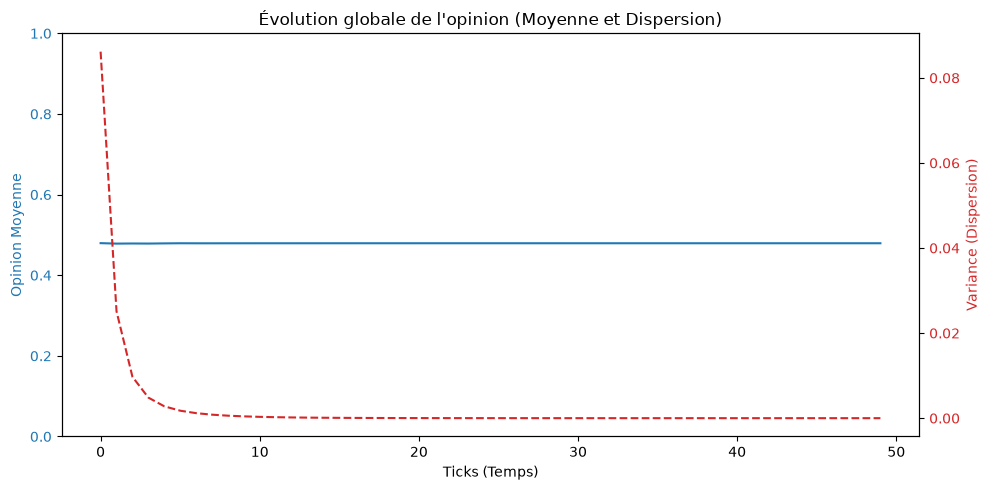

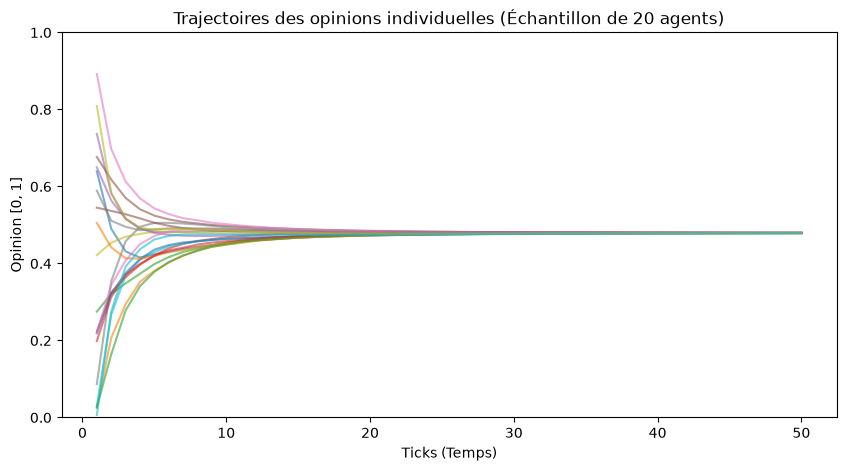

In [4]:
# Paramètres du modèle
WIDTH = 10
HEIGHT = 10
ALPHA = 0.5  # Modifiez alpha pour observer son impact sur la vitesse de convergence
STEPS = 50

# Création et exécution du modèle
model = OpinionModel(width=WIDTH, height=HEIGHT, alpha=ALPHA, seed=42)

for i in range(STEPS):
    model.step()

# Récupération des données collectées
model_data = model.datacollector.get_model_vars_dataframe()
agent_data = model.datacollector.get_agent_vars_dataframe()

# Affichage des résultats globaux (Moyenne et Variance)
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Ticks (Temps)')
ax1.set_ylabel('Opinion Moyenne', color=color)
ax1.plot(model_data.index, model_data['Opinion Moyenne'], color=color, label="Moyenne")
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Variance (Dispersion)', color=color)
ax2.plot(model_data.index, model_data['Variance (Dispersion)'], color=color, linestyle='--', label="Variance")
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Évolution globale de l'opinion (Moyenne et Dispersion)")
fig.tight_layout()
plt.show()

# Affichage des trajectoires individuelles (Polarisation vs Consensus)
# On prend un échantillon de 20 agents pour la lisibilité
agent_opinions = agent_data.unstack(level=1)['Opinion']
sample_agents = agent_opinions.columns[:20]

plt.figure(figsize=(10, 5))
for agent_id in sample_agents:
    plt.plot(agent_opinions.index, agent_opinions[agent_id], alpha=0.6)

plt.title("Trajectoires des opinions individuelles (Échantillon de 20 agents)")
plt.xlabel("Ticks (Temps)")
plt.ylabel("Opinion [0, 1]")
plt.ylim(0, 1)
plt.show()

## 5. Questions d'analyse et de compréhension

**Compréhension théorique (Dynamique des systèmes complexes)**
* Quel est l'impact précis du paramètre d'influence $\alpha$ sur la vitesse de convergence globale ? Que se passe-t-il visuellement sur le graphique si $\alpha$ est très proche de 0, ou à l'inverse, égal à 1 ?
* Dans le modèle actuel, le système finit presque toujours par converger vers un consensus global. Quel mécanisme mathématique de la méthode `step()` (mise à jour de l'opinion) rend la polarisation ou la création de groupes impossible à long terme avec cette configuration exacte ?
* En vous basant sur le protocole ODD, expliquez avec vos propres mots comment la notion d'"émergence" se manifeste dans les graphiques que vous avez générés. 

**Technique et manipulation de Mesa 3**
* Comment l'activation des agents est-elle gérée dans la nouvelle syntaxe de Mesa 3 (`self.agents.shuffle_do("step")`) par rapport aux itérations classiques sur des listes ? Quel est l'intérêt de l'ordre aléatoire ici ?
* Expliquez la différence entre `model_reporters` et `agent_reporters` lors de l'instanciation du `DataCollector`. Pourquoi est-il indispensable d'utiliser les deux pour observer à la fois le consensus et la dispersion ?
* Si un agent se trouve sur le bord de la grille (par exemple en `x=0`), comment le paramètre `torus=True` du `MultiGrid` affecte-t-il la récupération de ses voisins ?

**Ouverture et esprit critique (Pour aller plus loin)**
* Comment modifieriez-vous le code de l'agent pour introduire un "biais de confirmation" (c'est-à-dire qu'un agent n'est influencé par un voisin que si l'écart entre leurs deux opinions est inférieur à un seuil de tolérance $\epsilon$) ? Quel phénomène social émergerait alors ?
* Si nous devions modéliser un véritable réseau social (comme un graphe d'abonnés) plutôt qu'une grille spatiale, quelle structure topologique de Mesa utiliseriez-vous pour modéliser des "influenceurs" très connectés face à des utilisateurs isolés ?

## 6. Réponses aux questions

Pour répondre avec des mesures plutôt qu'avec des intuitions, je réutilise le modèle du TP en lui ajoutant trois choses :
- un reporter **`Ecart max-min`** (écart entre l'opinion la plus haute et la plus basse) ;
- un paramètre **`epsilon`** optionnel pour le biais de confirmation (Q7) ;
- une collecte de l'état initial (tick 0) dans `__init__`, puis une collecte **après** chaque tick. Dans le modèle du prof, la collecte a lieu avant que les agents agissent, donc l'état final n'est jamais enregistré.

Sans `epsilon`, l'agent se comporte exactement comme `CitizenAgent`.

In [5]:
import networkx as nx

SEED = 42


class CitizenAgentQ(CitizenAgent):
    """CitizenAgent + biais de confirmation optionnel.

    epsilon=None : modèle du TP, l'agent est influencé par tous ses voisins.
    epsilon=x    : seuls les voisins tels que |o_j - o_i| < x comptent.
    """
    def __init__(self, model, alpha, epsilon=None):
        super().__init__(model, alpha)
        self.epsilon = epsilon

    def voisins(self):
        return self.model.grid.get_neighbors(self.pos, moore=True, include_center=False)

    def step(self):
        neighbors = self.voisins()
        if self.epsilon is not None:
            neighbors = [n for n in neighbors if abs(n.opinion - self.opinion) < self.epsilon]
        if len(neighbors) > 0:
            mean_opinion = np.mean([n.opinion for n in neighbors])
            self.opinion = self.opinion + self.alpha * (mean_opinion - self.opinion)


class OpinionModelQ(mesa.Model):
    """OpinionModel avec epsilon, torus réglable et un reporter de plus."""
    def __init__(self, width, height, alpha=0.2, epsilon=None, torus=True, seed=None):
        super().__init__(rng=seed)
        self.grid = mesa.space.MultiGrid(width, height, torus=torus)
        for _, (x, y) in self.grid.coord_iter():
            self.grid.place_agent(CitizenAgentQ(self, alpha, epsilon), (x, y))
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Opinion Moyenne": lambda m: np.mean([a.opinion for a in m.agents]),
                "Variance (Dispersion)": lambda m: np.var([a.opinion for a in m.agents]),
                "Ecart max-min": lambda m: np.ptp([a.opinion for a in m.agents]),
            },
            agent_reporters={"Opinion": "opinion"},
        )
        self.datacollector.collect(self)   # état initial (tick 0)

    def step(self):
        self.agents.shuffle_do("step")
        self.datacollector.collect(self)   # état à la fin du tick


def simuler(model, steps):
    for _ in range(steps):
        model.step()
    return (model.datacollector.get_model_vars_dataframe(),
            model.datacollector.get_agent_vars_dataframe())


def tick_convergence(model_data, seuil=1e-4):
    """Premier tick où la variance passe sous le seuil (None si jamais)."""
    sous = model_data.index[model_data["Variance (Dispersion)"] < seuil]
    return int(sous[0]) if len(sous) else None


def tracer_trajectoires(ax, agent_data, n=20, titre=""):
    traj = agent_data["Opinion"].unstack(level=1)
    for agent_id in traj.columns[:n]:
        ax.plot(traj.index, traj[agent_id], alpha=0.6, linewidth=1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Ticks (Temps)")
    ax.set_ylabel("Opinion [0, 1]")
    ax.set_title(titre)

### Q1. Impact de $\alpha$ sur la vitesse de convergence

Même grille 10×10 et même graine : seul $\alpha$ change. On mesure le premier tick où la variance passe sous $10^{-4}$.

In [6]:
ALPHAS = [0.01, 0.1, 0.5, 1.0]
res_alpha = {a: simuler(OpinionModelQ(10, 10, alpha=a, seed=SEED), 200) for a in ALPHAS}

tableau = pd.DataFrame({
    "variance au tick 10": [md_["Variance (Dispersion)"].iloc[10] for md_, _ in res_alpha.values()],
    "tick où variance < 1e-4": [tick_convergence(md_) or "> 200" for md_, _ in res_alpha.values()],
}, index=pd.Index(ALPHAS, name="alpha"))
tableau

,variance au tick 10,tick où variance < 1e-4
alpha,,
0.01,0.070843,> 200
0.10,0.014449,87
0.50,0.000311,14
1.00,0.000012,7


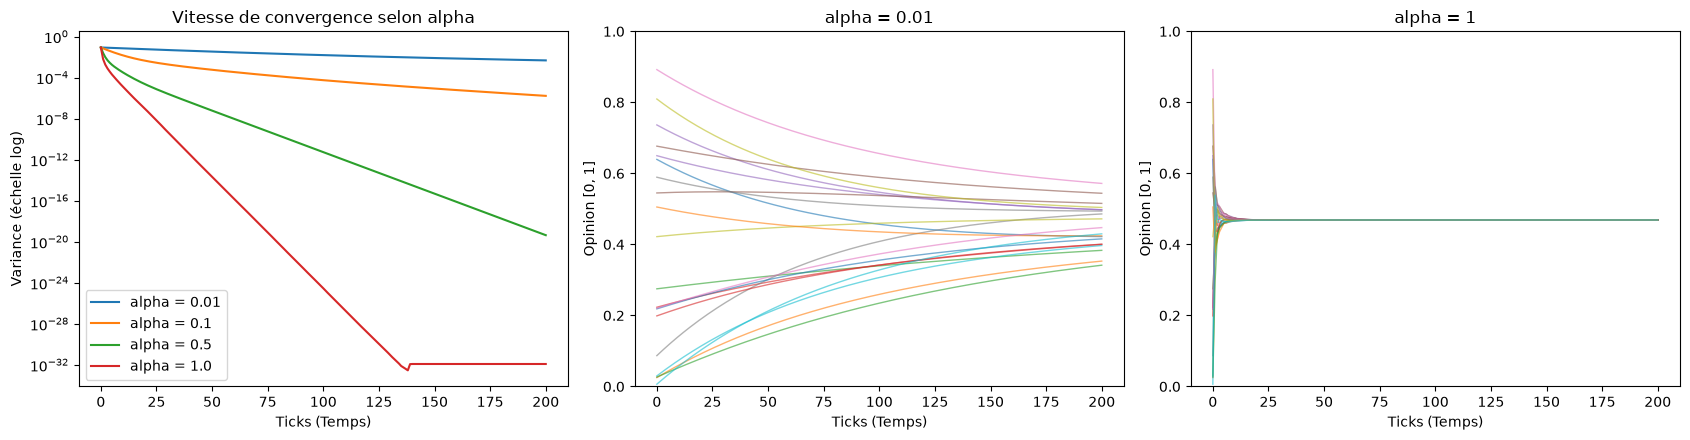

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (md_, _) in res_alpha.items():
    axes[0].plot(md_.index, md_["Variance (Dispersion)"], label=f"alpha = {a}")
axes[0].set_yscale("log")
axes[0].set_xlabel("Ticks (Temps)")
axes[0].set_ylabel("Variance (échelle log)")
axes[0].set_title("Vitesse de convergence selon alpha")
axes[0].legend()
tracer_trajectoires(axes[1], res_alpha[0.01][1], titre="alpha = 0.01")
tracer_trajectoires(axes[2], res_alpha[1.0][1], titre="alpha = 1")
plt.tight_layout()
plt.show()

**Réponse Q1.** La règle $o_i^{t+1} = o_i^t + \alpha(\bar{o}_{\mathcal{N}_i}^t - o_i^t)$ montre que $\alpha$ est la **fraction de l'écart** avec ses voisins que l'agent comble à chaque tick. $\alpha$ fixe donc la **vitesse** de convergence, mais pas son issue : pour tout $\alpha > 0$, la population finit par un consensus.

| $\alpha$ | tick où la variance passe sous $10^{-4}$ |
|---|---|
| 0.01 | plus de 200 |
| 0.1 | 87 |
| 0.5 | 14 |
| 1 | 7 |

- **$\alpha$ proche de 0** : les agents bougent à peine. Les trajectoires restent presque horizontales, la variance diminue très lentement (0.071 au tick 10, contre 0.086 au départ) et le consensus demande des centaines de ticks. Avec $\alpha = 0$, rien ne bougerait.
- **$\alpha = 1$** : chaque agent **remplace** son opinion par la moyenne de ses voisins. Les courbes se resserrent brutalement dès les premiers ticks, et la variance passe sous $10^{-4}$ en 7 ticks. L'agent oublie complètement son avis précédent : c'est un lissage pur de la grille.

### Q2. Pourquoi la polarisation est impossible avec cette règle

In [8]:
model_q = OpinionModelQ(10, 10, alpha=0.5, seed=SEED)
md_q, ad_q = simuler(model_q, 50)
ecart = md_q["Ecart max-min"]
print(f"Écart max-min : {ecart.iloc[0]:.4f} (tick 0) -> {ecart.iloc[-1]:.2e} (tick 50)")
print(f"Plus forte variation de l'écart d'un tick au suivant : {np.diff(ecart.values).max():.2e}")

Écart max-min : 0.9910 (tick 0) -> 9.39e-04 (tick 50)
Plus forte variation de l'écart d'un tick au suivant : -9.57e-05


**Réponse Q2.** La nouvelle opinion est une **moyenne pondérée** de l'ancienne opinion et de la moyenne des voisins : $o_i^{t+1} = (1-\alpha)\,o_i^t + \alpha\,\bar{o}_{\mathcal{N}_i}^t$, avec des poids positifs dont la somme vaut 1. Une moyenne de valeurs reste toujours **entre la plus petite et la plus grande** de ces valeurs. Conséquences :
1. un agent ne peut jamais dépasser l'opinion la plus extrême de la population. L'écart max-min ne peut donc **que diminuer**, et c'est ce qu'on mesure : il passe de 0.99 à $9 \times 10^{-4}$ en 50 ticks, sans **aucune** hausse d'un tick à l'autre ;
2. chaque agent écoute **tous** ses voisins, quel que soit leur désaccord. Il n'y a ni rejet ni répulsion, et la grille torique est connexe : de proche en proche, les opinions se mélangent dans toute la population.

Aucune force n'éloigne deux opinions : deux camps ne peuvent donc pas se former durablement. Il faudrait une règle qui **ignore** certains voisins (Q7) ou des agents qui ne bougent pas (Q8).

### Q3. L'émergence dans les graphiques

**Réponse Q3.** L'émergence, au sens du protocole ODD, est un comportement **global** qui n'est écrit nulle part dans la règle **individuelle**. Ici, aucun agent ne connaît l'opinion moyenne de la population, et aucun ne cherche à atteindre un consensus : chacun ne regarde que ses 8 voisins. Pourtant, dans les graphiques de la section 4 :
- la **courbe de variance** (en rouge) chute vers 0 : toute la population finit par partager la même opinion. Ce consensus est le phénomène émergent ;
- les **trajectoires individuelles** partent de valeurs dispersées entre 0 et 1 et se rejoignent en un seul faisceau, sans chef ni coordination centrale ;
- l'**opinion moyenne** (en bleu) reste presque constante (vers 0.48). Le consensus ne va pas vers 0 ou vers 1 : il se fixe près de la moyenne de départ, que personne n'a calculée.

Le niveau micro (la règle locale) produit donc un niveau macro (le consensus) qui n'est pas programmé.

### Q4. Activation avec `self.agents.shuffle_do("step")`

In [9]:
print("Ordre d'un tick       :", [a.unique_id for a in model_q.agents.shuffle()][:10])
print("Ordre du tick suivant :", [a.unique_id for a in model_q.agents.shuffle()][:10])

Ordre d'un tick       : [3, 68, 51, 11, 62, 45, 81, 4, 69, 52]
Ordre du tick suivant : [93, 13, 89, 84, 17, 41, 52, 28, 38, 60]


**Réponse Q4.** Dans Mesa 3, les agents s'enregistrent automatiquement dans `self.agents` (un `AgentSet`) au moment de `super().__init__(model)`. `shuffle_do("step")` **mélange** cet ensemble, puis appelle `step()` sur chaque agent. Cela remplace à la fois l'ancien `RandomActivation` et une boucle `for agent in liste: agent.step()`.

L'ordre aléatoire est important parce que la mise à jour est **asynchrone** : un agent qui joue après ses voisins voit leurs opinions **déjà modifiées** pendant ce tick. Avec un ordre fixe (toujours de l'agent 1 à l'agent 100), les mêmes agents profiteraient toujours de cette information et l'opinion se propagerait toujours dans le même sens sur la grille : on créerait un **biais artificiel** lié à l'ordre de création. Les sorties ci-dessus montrent que l'ordre change à chaque tick. Sur l'ensemble de la simulation, aucun agent n'est donc avantagé.

### Q5. `model_reporters` et `agent_reporters`

In [10]:
print("model_reporters :", md_q.shape, "->", list(md_q.columns))
print("agent_reporters :", ad_q.shape, "index", list(ad_q.index.names), "->", list(ad_q.columns))
ad_q.head()

model_reporters : (51, 3) -> ['Opinion Moyenne', 'Variance (Dispersion)', 'Ecart max-min']
agent_reporters : (5100, 1) index ['Step', 'AgentID'] -> ['Opinion']


Opinion
Step AgentID          
0.0  1        0.639427
     2        0.025011
     3        0.275029
     4        0.223211
     5        0.736471

**Réponse Q5.**
- **`model_reporters`** calcule **une valeur par tick pour tout le modèle**. On obtient un tableau de 51 lignes (ticks 0 à 50) : opinion moyenne, variance, écart max-min.
- **`agent_reporters`** enregistre **une valeur par agent et par tick**. On obtient 5 100 lignes (51 ticks × 100 agents), indexées par `(Step, AgentID)`.

Les deux sont nécessaires, parce que chacun cache ce que l'autre montre. La **moyenne** seule ne distingue pas un consensus à 0.5 d'une population coupée en deux camps à 0 et à 1 : les deux donnent 0.5. La **variance** indique s'il y a dispersion, mais pas sa forme (deux camps nets, ou beaucoup de petits groupes ?). Seules les **trajectoires individuelles** (`agent_reporters`) montrent qui converge vers quoi : c'est ce qui permet de voir les groupes de la Q7. À l'inverse, 5 100 lignes ne se lisent pas sans indicateurs résumés.

### Q6. `torus=True` et les agents du bord

In [11]:
for torus in (True, False):
    grille = mesa.space.MultiGrid(10, 10, torus=torus)
    voisins = sorted(grille.get_neighborhood((0, 0), moore=True, include_center=False))
    print(f"torus={torus!s:<5} : {len(voisins)} voisins de (0, 0) -> {voisins}")

torus=True  : 8 voisins de (0, 0) -> [(0, 1), (0, 9), (1, 0), (1, 1), (1, 9), (9, 0), (9, 1), (9, 9)]
torus=False : 3 voisins de (0, 0) -> [(0, 1), (1, 0), (1, 1)]


**Réponse Q6.** Avec `torus=True`, la grille est **refermée sur elle-même** : le bord gauche touche le bord droit, et le bas touche le haut. L'agent en `(0, 0)` a donc **8 voisins**, comme tous les autres : ses voisins en `x = -1` deviennent ceux de la colonne `x = 9`, et ceux de `y = -1` ceux de la ligne `y = 9`. Avec `torus=False`, il n'en a que **3**, et un agent sur un bord (hors coin) n'en a que 5.

Le tore supprime donc les **effets de bord** : tous les agents ont le même nombre de voisins et donc le même poids dans la dynamique. Sans tore, les agents des coins et des bords seraient moins influencés et plus lents à converger.

### Q7. Biais de confirmation (confiance bornée)

Modification de `step()` (déjà présente dans `CitizenAgentQ`) : on filtre les voisins **avant** de calculer la moyenne.
```python
neighbors = [n for n in neighbors if abs(n.opinion - self.opinion) < self.epsilon]
```
Si aucun voisin n'est assez proche, l'agent ne bouge pas. Pour voir des groupes, j'utilise une grille plus grande (20×20) et 1000 ticks, car ce modèle se stabilise lentement. Un **groupe** est un ensemble d'agents voisins dont l'écart d'opinion reste inférieur à $\epsilon$ : ils continuent de s'influencer entre eux.

In [12]:
def groupes_influence(model, epsilon):
    """Tailles des groupes d'agents voisins qui s'influencent encore (|écart| < epsilon)."""
    g = nx.Graph()
    g.add_nodes_from(model.agents)
    for a in model.agents:
        for v in a.voisins():
            if abs(a.opinion - v.opinion) < epsilon:
                g.add_edge(a, v)
    return sorted((len(c) for c in nx.connected_components(g)), reverse=True)


EPSILONS = [0.05, 0.15, 0.3, 1.0]
COTE = 20
TAILLE_MIN = int(0.05 * COTE * COTE)   # un « grand groupe » = au moins 5 % de la population
res_eps, lignes = {}, []
for eps in EPSILONS:
    m = OpinionModelQ(COTE, COTE, alpha=0.5, epsilon=eps, seed=SEED)
    md_, ad_ = simuler(m, 1000)
    carte = np.zeros((COTE, COTE))
    for a in m.agents:
        x, y = a.pos
        carte[y, x] = a.opinion
    tailles = groupes_influence(m, eps)
    res_eps[eps] = (ad_, carte, sum(t >= TAILLE_MIN for t in tailles))
    lignes.append({"epsilon": eps, "groupes": len(tailles),
                   f"grands groupes (>= {TAILLE_MIN})": sum(t >= TAILLE_MIN for t in tailles),
                   "plus grand groupe": f"{tailles[0] / COTE**2:.0%}",
                   "agents isolés": tailles.count(1),
                   "variance finale": f"{md_['Variance (Dispersion)'].iloc[-1]:.2e}"})
pd.DataFrame(lignes).set_index("epsilon")

,groupes,grands groupes (>= 20),plus grand groupe,agents isolés,variance finale
epsilon,,,,,
0.05,254,0,3%,180,8.74e-02
0.15,29,2,70%,17,3.04e-02
0.30,2,1,100%,1,6.16e-04
1.00,1,1,100%,0,1.63e-24


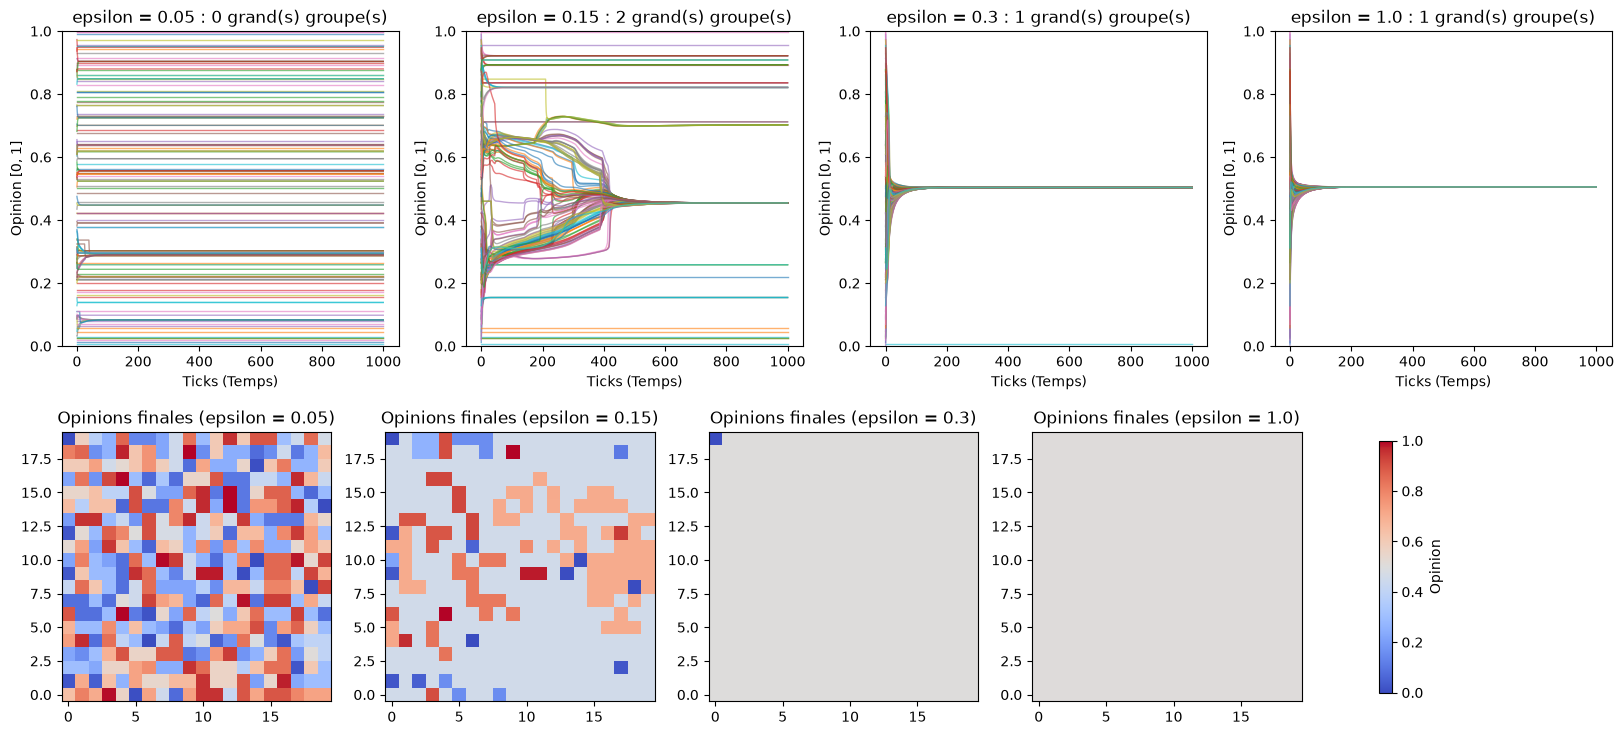

In [13]:
fig, axes = plt.subplots(2, len(EPSILONS), figsize=(5 * len(EPSILONS), 9))
for i, (eps, (ad_, carte, grands)) in enumerate(res_eps.items()):
    tracer_trajectoires(axes[0, i], ad_, n=150, titre=f"epsilon = {eps} : {grands} grand(s) groupe(s)")
    im = axes[1, i].imshow(carte, origin="lower", cmap="coolwarm", vmin=0, vmax=1)
    axes[1, i].set_title(f"Opinions finales (epsilon = {eps})")
fig.colorbar(im, ax=axes[1, :].tolist(), shrink=0.8, label="Opinion")
plt.show()

**Réponse Q7.** Avec le biais de confirmation, un agent n'écoute que les voisins **déjà proches de son avis**. Deux voisins trop éloignés ($|o_j - o_i| \geq \epsilon$) cessent de s'influencer, et la force qui ramenait tout le monde vers le centre disparaît. Il s'agit du modèle de **confiance bornée** (Deffuant, Hegselmann-Krause). Selon $\epsilon$ :

| $\epsilon$ | ce qu'on observe | phénomène social |
|---|---|---|
| 1.0 | 1 seul groupe (100 %), variance ≈ 0 | **consensus** : on retrouve le modèle de base |
| 0.3 | 1 groupe de 100 %, un seul agent isolé | consensus, avec un extrémiste en coin de grille |
| 0.15 | 2 grands groupes (le principal en rassemble 70 %, vers 0.45 ; un second vers 0.70), et 17 agents isolés aux extrêmes | **polarisation** : une majorité, une minorité qui ne se parlent plus, et des extrémistes |
| 0.05 | 254 groupes, aucun grand, 180 agents isolés | **fragmentation** : chacun reste dans sa bulle |

Les cartes finales montrent aussi des **régions** d'opinion homogène sur la grille : ce sont les **chambres d'écho** (ou bulles de filtre) des réseaux sociaux. Plus la tolérance $\epsilon$ est faible, plus la société se divise. Les agents aux opinions extrêmes, qui n'ont aucun voisin assez proche, ne changent jamais d'avis.

### Q8. Réseau social avec influenceurs : `NetworkGrid`

Mesa propose `mesa.space.NetworkGrid`, qui place les agents sur les **nœuds d'un graphe NetworkX** : les voisins d'un agent sont alors ses **connexions**, et non les cases autour de lui. Pour avoir des influenceurs, le graphe doit être **sans échelle**. Le modèle de **Barabási-Albert** (attachement préférentiel : un nouvel utilisateur se connecte de préférence aux comptes déjà populaires) produit quelques hubs très connectés et une majorité d'utilisateurs avec 2 ou 3 liens.

Expérience : 300 utilisateurs. On rend 5 agents « têtus » (opinion fixée à 1, $\alpha = 0$) : soit les 5 hubs, soit 5 utilisateurs périphériques. On suit ensuite l'opinion moyenne des 295 autres.

In [14]:
class NetworkCitizenAgent(CitizenAgentQ):
    """Même règle d'opinion, mais les voisins sont les connexions dans le graphe."""
    def voisins(self):
        return self.model.grid.get_neighbors(self.pos, include_center=False)


class NetworkOpinionModel(mesa.Model):
    def __init__(self, n=300, m=2, alpha=0.5, seed=None):
        super().__init__(rng=seed)
        self.graphe = nx.barabasi_albert_graph(n, m, seed=seed)
        self.grid = mesa.space.NetworkGrid(self.graphe)
        for noeud in self.graphe.nodes:
            self.grid.place_agent(NetworkCitizenAgent(self, alpha), noeud)

    def agent_du_noeud(self, noeud):
        return self.grid.get_cell_list_contents([noeud])[0]

    def step(self):
        self.agents.shuffle_do("step")


N_RESEAU, N_TETUS, STEPS_RESEAU = 300, 5, 30
degres = dict(NetworkOpinionModel(n=N_RESEAU, seed=SEED).graphe.degree())
par_degre = sorted(degres, key=degres.get)
hubs, peripheriques = par_degre[-N_TETUS:], par_degre[:N_TETUS]
print(f"Degré médian = {int(np.median(list(degres.values())))}, degré max = {max(degres.values())}")
print("Degrés des 5 hubs          :", [degres[n] for n in hubs])
print("Degrés des 5 périphériques :", [degres[n] for n in peripheriques])


def campagne(noeuds_tetus):
    """Les agents de `noeuds_tetus` défendent l'opinion 1 sans jamais changer d'avis."""
    m = NetworkOpinionModel(n=N_RESEAU, seed=SEED)
    tetus = [m.agent_du_noeud(n) for n in noeuds_tetus]
    for a in tetus:
        a.opinion, a.alpha = 1.0, 0.0
    autres = [a for a in m.agents if a not in tetus]
    moyennes = [np.mean([a.opinion for a in autres])]
    for _ in range(STEPS_RESEAU):
        m.step()
        moyennes.append(np.mean([a.opinion for a in autres]))
    return moyennes


scenarios = {"Aucun agent têtu": campagne([]),
             "5 hubs têtus (influenceurs)": campagne(hubs),
             "5 périphériques têtus": campagne(peripheriques)}
pd.DataFrame({nom: [v[0], v[10], v[-1]] for nom, v in scenarios.items()},
             index=["tick 0", "tick 10", f"tick {STEPS_RESEAU}"]).T.round(3)

Degré médian = 3, degré max = 55
Degrés des 5 hubs          : [16, 24, 43, 45, 55]
Degrés des 5 périphériques : [2, 2, 2, 2, 2]


,tick 0,tick 10,tick 30
Aucun agent têtu,0.493,0.482,0.482
5 hubs têtus (influenceurs),0.493,0.766,0.939
5 périphériques têtus,0.493,0.501,0.545


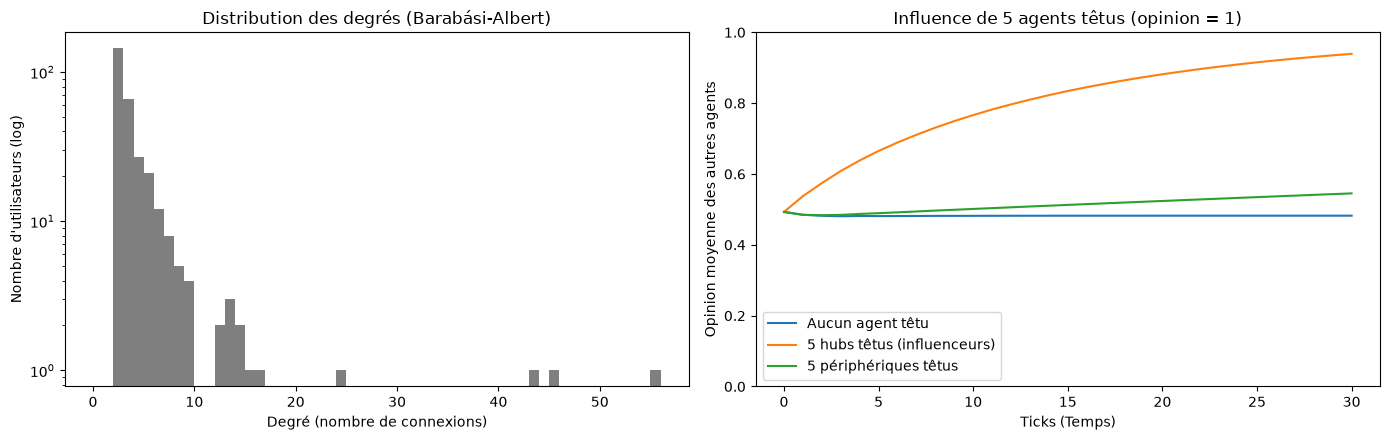

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.hist(list(degres.values()), bins=range(0, max(degres.values()) + 2), color="tab:gray")
ax1.set_yscale("log")
ax1.set_xlabel("Degré (nombre de connexions)")
ax1.set_ylabel("Nombre d'utilisateurs (log)")
ax1.set_title("Distribution des degrés (Barabási-Albert)")
for nom, moyennes in scenarios.items():
    ax2.plot(range(len(moyennes)), moyennes, label=nom)
ax2.set_ylim(0, 1)
ax2.set_xlabel("Ticks (Temps)")
ax2.set_ylabel("Opinion moyenne des autres agents")
ax2.set_title("Influence de 5 agents têtus (opinion = 1)")
ax2.legend()
plt.tight_layout()
plt.show()

**Réponse Q8.** On utiliserait **`mesa.space.NetworkGrid`** avec un **graphe sans échelle** (Barabási-Albert). La distribution des degrés le confirme : le degré médian est 3, mais le plus gros hub a **55 connexions**. Ce sont les influenceurs.

| 5 agents têtus (opinion = 1) | opinion moyenne des autres : tick 0 → 10 → 30 |
|---|---|
| aucun | 0.493 → 0.482 → 0.482 |
| les 5 **hubs** (degrés 16 à 55) | 0.493 → 0.766 → **0.939** |
| 5 **périphériques** (degré 2) | 0.493 → 0.501 → 0.545 |

Avec le **même nombre** d'agents têtus, les 5 hubs entraînent presque toute la population vers leur opinion en 30 ticks, alors que 5 utilisateurs isolés la déplacent à peine. Dans un réseau, ce n'est pas le nombre de personnes qui compte, mais leur **position** : un hub fait partie du voisinage de dizaines d'agents, qui transmettent à leur tour son opinion. Une grille ne permet pas de voir cela, car chaque case a exactement 8 voisins.

## 7. Conclusion

- Une règle **locale et simple** (se rapprocher de la moyenne de ses voisins) produit un **consensus global** sans coordination centrale : c'est l'émergence. $\alpha$ règle seulement la vitesse de convergence (7 ticks pour $\alpha = 1$, plus de 200 pour $\alpha = 0.01$).
- Ce consensus est **garanti** par la règle elle-même : une moyenne ne peut pas sortir de l'intervalle des opinions existantes, donc l'écart entre les extrêmes ne fait que diminuer.
- Il suffit d'ajouter une **tolérance limitée** ($\epsilon$) pour voir apparaître la polarisation puis la fragmentation, et une **topologie réaliste** (graphe sans échelle) pour que quelques influenceurs pèsent plus que toute la périphérie.

**Remarque technique (Mesa 3.5).** Le code fourni utilisait `for _, x, y in self.grid.coord_iter()` et `super().__init__(seed=seed)`. Avec Mesa 3.5, `coord_iter()` renvoie `(contenu, (x, y))` et le paramètre s'appelle `rng`. Les deux lignes ont été corrigées dans la section 3.